# FarmPulse - Test evaluation and Grad-CAM

Cette étape mesure la généralisation sur le test set et explique visuellement une prédiction. Elle doit être exécutée après l'entraînement.

In [10]:
from pathlib import Path
import sys, json, torch, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from PIL import Image
from torchvision import transforms
from src.models.model import create_model
from src.utils.gradcam import GradCAM

payload = torch.load(ROOT / 'models' / 'best.pt', map_location='cpu', weights_only=False)
classes = payload['classes']; model = create_model(len(classes), pretrained=False); model.load_state_dict(payload['state_dict']); model.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

In [11]:
from src.models.evaluate import evaluate
metrics = evaluate(
    ROOT / 'models' / 'best.pt',
    ROOT / 'data' / 'processed',
    ROOT / 'models',
    split="val"
)

print('Validation accuracy:', metrics['accuracy'])
print('Validation F1:', metrics['f1_weighted'])

Validation accuracy: 0.9961227786752828
Validation F1: 0.996122775623225


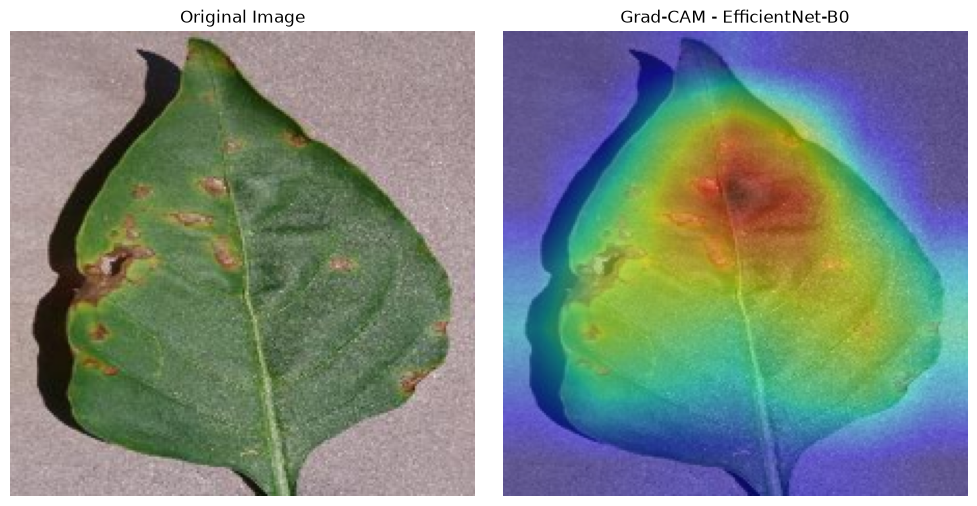

In [16]:

# Grad-CAM visualization for EfficientNet-B0

import torch
import matplotlib.pyplot as plt
import numpy as np

from PIL import Image
from torchvision import transforms
from src.utils.gradcam import GradCAM

# 1. Select target layer (last convolutional block)
target_layer = model.features[-2]

# 2. Initialize Grad-CAM
cam = GradCAM(model, target_layer)

# 3. Select one validation image
import csv

val_csv = ROOT / "data" / "processed" / "val.csv"

with val_csv.open(encoding="utf-8") as f:
    row = next(csv.DictReader(f))

image_path = Path(row["path"])
if not image_path.is_absolute():
    image_path = ROOT / image_path

image = Image.open(image_path).convert("RGB")

# 4. Preprocess image
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.485, 0.456, 0.406),
        (0.229, 0.224, 0.225)
    ),
])

tensor = transform(image).unsqueeze(0)

# 5. Generate Grad-CAM heatmap
with torch.enable_grad():
    heatmap = cam(tensor)[0].detach().cpu().numpy()

# 6. Normalize heatmap
heatmap = (heatmap - heatmap.min()) / (
    heatmap.max() - heatmap.min() + 1e-8
)

# 7. Display original image and Grad-CAM
heatmap_img = Image.fromarray(
    (heatmap * 255).astype(np.uint8)
).resize((224, 224), Image.Resampling.BILINEAR)

heatmap_resized = np.array(heatmap_img) / 255.0

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image.resize((224, 224)))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image.resize((224, 224)))
plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
plt.title("Grad-CAM - EfficientNet-B0")
plt.axis("off")

plt.tight_layout()
plt.show()


In [13]:
print("CSV columns:", list(row.keys()))
print("Selected row:", row)

CSV columns: ['path', 'label', 'class_name']
Selected row: {'path': 'C:\\Users\\HP\\Desktop\\farmpulse\\data\\raw\\Pepper__bell___Bacterial_spot\\c955b22e-69b7-4062-96ef-431fe8c37690___JR_B.Spot 8993.JPG', 'label': '0', 'class_name': 'Pepper__bell___Bacterial_spot'}


In [17]:
# Get model prediction
model.eval()

with torch.no_grad():
    logits = model(tensor)
    probabilities = torch.softmax(logits, dim=1)

pred_idx = int(probabilities.argmax(dim=1).item())
confidence = float(probabilities[0, pred_idx].item())

true_idx = int(row["label"])
true_class = row["class_name"]
predicted_class = classes[pred_idx]

print("True class:", true_class)
print("Predicted class:", predicted_class)
print("Confidence:", f"{confidence:.2%}")
print("Correct prediction:", true_idx == pred_idx)

True class: Pepper__bell___Bacterial_spot
Predicted class: Pepper__bell___Bacterial_spot
Confidence: 100.00%
Correct prediction: True


In [15]:
print("Checkpoint classes:")
for i, name in enumerate(classes):
    print(i, name)

print("\nTrue label ID:", row["label"])
print("True class from CSV:", row["class_name"])
print("Class at ID 14 in checkpoint:", classes[14])

Checkpoint classes:
0 Pepper__bell___Bacterial_spot
1 Pepper__bell___healthy
2 Potato___Early_blight
3 Potato___Late_blight
4 Potato___healthy
5 Tomato_Bacterial_spot
6 Tomato_Early_blight
7 Tomato_Late_blight
8 Tomato_Leaf_Mold
9 Tomato_Septoria_leaf_spot
10 Tomato_Spider_mites_Two_spotted_spider_mite
11 Tomato__Target_Spot
12 Tomato__Tomato_YellowLeaf__Curl_Virus
13 Tomato__Tomato_mosaic_virus
14 Tomato_healthy

True label ID: 0
True class from CSV: Pepper__bell___Bacterial_spot
Class at ID 14 in checkpoint: Tomato_healthy


In [18]:
import csv

val_csv = ROOT / "data" / "processed" / "val.csv"

target_classes = [
    "Pepper__bell___Bacterial_spot",
    "Tomato_healthy",
    "Tomato_Early_blight"
]

selected_rows = {}

with val_csv.open(encoding="utf-8") as f:
    for row in csv.DictReader(f):
        class_name = row["class_name"]

        if class_name in target_classes and class_name not in selected_rows:
            selected_rows[class_name] = row

for class_name, row in selected_rows.items():
    print("Class:", class_name)
    print("Image:", row["path"])
    print("-" * 50)

Class: Pepper__bell___Bacterial_spot
Image: C:\Users\HP\Desktop\farmpulse\data\raw\Pepper__bell___Bacterial_spot\c955b22e-69b7-4062-96ef-431fe8c37690___JR_B.Spot 8993.JPG
--------------------------------------------------
Class: Tomato_Early_blight
Image: C:\Users\HP\Desktop\farmpulse\data\raw\Tomato_Early_blight\69e0581c-14a5-42d8-ad48-4f689d05632f___RS_Erly.B 6432.JPG
--------------------------------------------------
Class: Tomato_healthy
Image: C:\Users\HP\Desktop\farmpulse\data\raw\Tomato_healthy\a8036d3b-eda1-4309-b2ac-5a409963f4d7___RS_HL 9840.JPG
--------------------------------------------------


Image 1
True class: Pepper__bell___Bacterial_spot
Predicted class: Pepper__bell___Bacterial_spot
Confidence: 100.00%
Correct: True
--------------------------------------------------
Image 2
True class: Tomato_Early_blight
Predicted class: Tomato_Early_blight
Confidence: 100.00%
Correct: True
--------------------------------------------------
Image 3
True class: Tomato_healthy
Predicted class: Tomato_healthy
Confidence: 100.00%
Correct: True
--------------------------------------------------


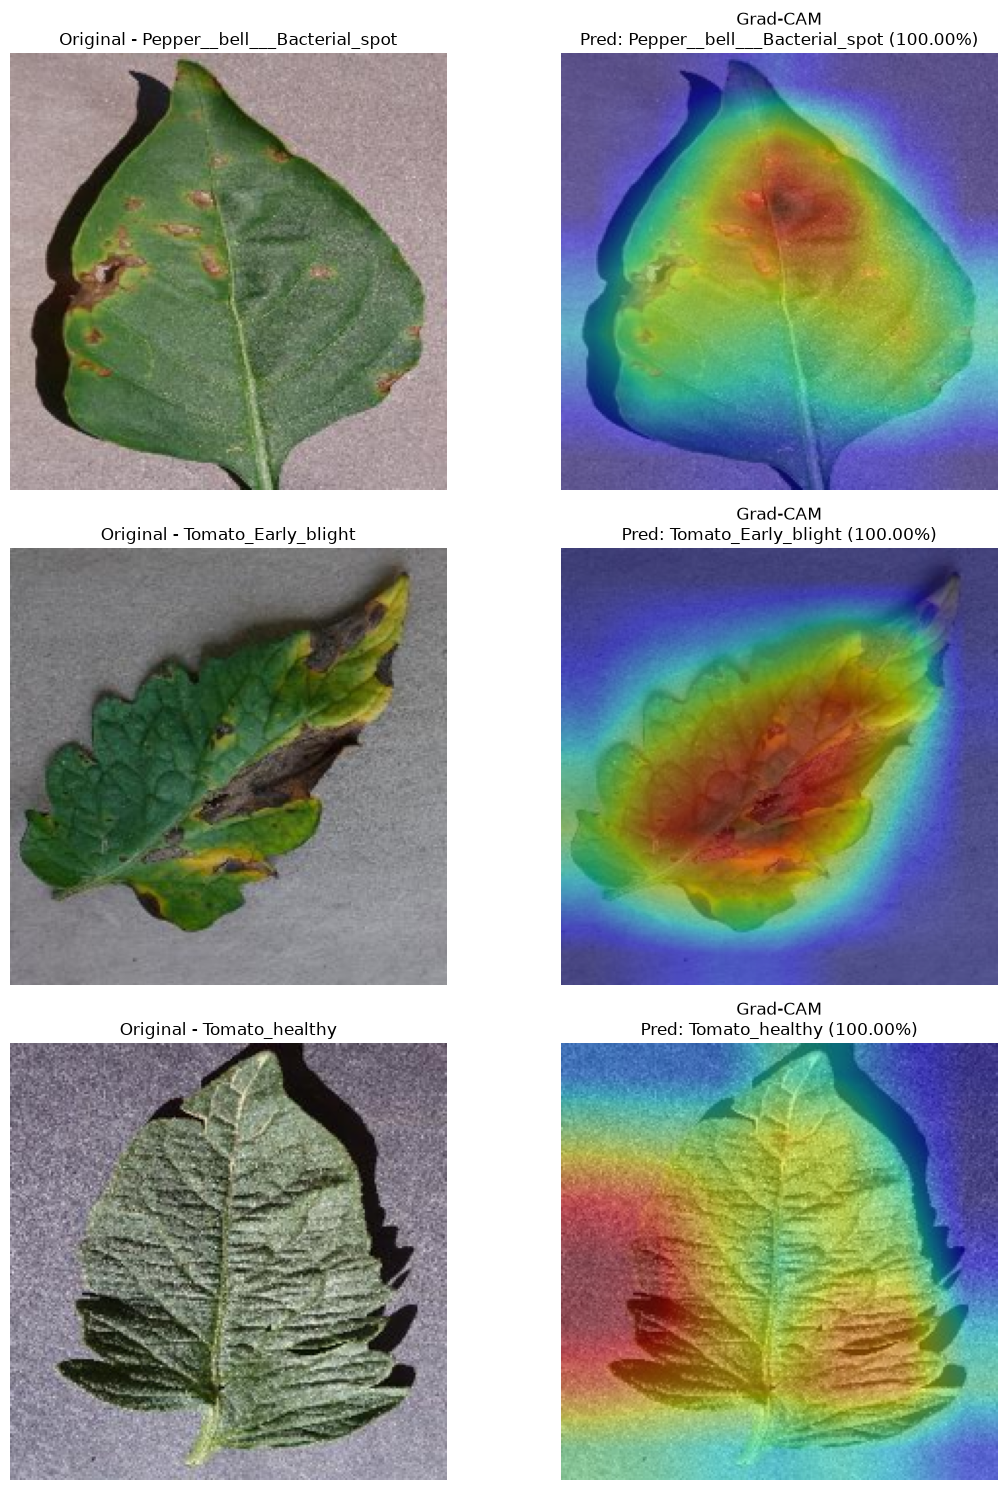

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision import transforms
from pathlib import Path

# Same preprocessing used during training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.485, 0.456, 0.406),
        (0.229, 0.224, 0.225)
    )
])

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for i, (class_name, row) in enumerate(selected_rows.items()):

    # Load image
    image_path = Path(row["path"])
    image = Image.open(image_path).convert("RGB")

    tensor = transform(image).unsqueeze(0)

    # Prediction
    model.eval()
    with torch.no_grad():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)

    pred_idx = int(probabilities.argmax(dim=1).item())
    confidence = float(probabilities[0, pred_idx].item())

    true_class = row["class_name"]
    predicted_class = classes[pred_idx]

    # Grad-CAM (requires gradients)
    with torch.enable_grad():
        heatmap = cam(tensor)[0].detach().cpu().numpy()

    # Normalize heatmap
    heatmap = (heatmap - heatmap.min()) / (
        heatmap.max() - heatmap.min() + 1e-8
    )

    heatmap_img = Image.fromarray(
        (heatmap * 255).astype(np.uint8)
    ).resize((224, 224), Image.Resampling.BILINEAR)

    heatmap_resized = np.array(heatmap_img) / 255.0

    # Display original
    axes[i, 0].imshow(image.resize((224, 224)))
    axes[i, 0].set_title(f"Original - {true_class}")
    axes[i, 0].axis("off")

    # Display Grad-CAM
    axes[i, 1].imshow(image.resize((224, 224)))
    axes[i, 1].imshow(heatmap_resized, cmap="jet", alpha=0.45)
    axes[i, 1].set_title(
        f"Grad-CAM\nPred: {predicted_class} ({confidence:.2%})"
    )
    axes[i, 1].axis("off")

    print(f"Image {i+1}")
    print("True class:", true_class)
    print("Predicted class:", predicted_class)
    print("Confidence:", f"{confidence:.2%}")
    print("Correct:", true_class == predicted_class)
    print("-" * 50)

plt.tight_layout()
plt.show()

In [20]:
output_dir = ROOT / "reports" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "gradcam_examples.png",
    dpi=300,
    bbox_inches="tight"
)

print("Grad-CAM figure saved successfully!")

Grad-CAM figure saved successfully!


Limitation actuelle: Grad-CAM est disponible côté PyTorch dans ce notebook. Son ajout dans la réponse FastAPI/Flutter est une étape d'intégration séparée.